C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.sparse import csr_matrix, issparse


Dataset Shape: (200, 5)

First 5 rows:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40
Standardized data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]
Linkage matrix created successfully.


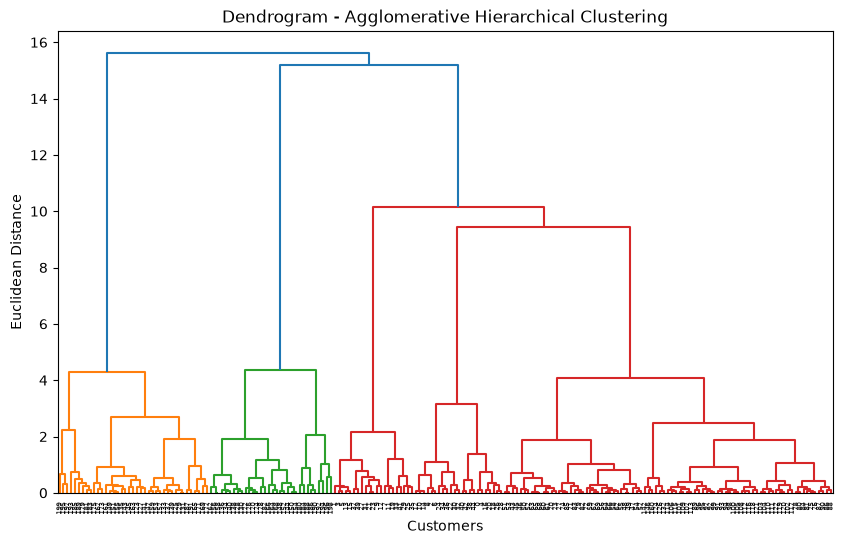

Cluster Assignments:
   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39        4
1           2                  15                      81        3
2           3                  16                       6        4
3           4                  16                      77        3
4           5                  17                      40        4
5           6                  17                      76        3
6           7                  18                       6        4
7           8                  18                      94        3
8           9                  19                       3        4
9          10                  19                      72        3


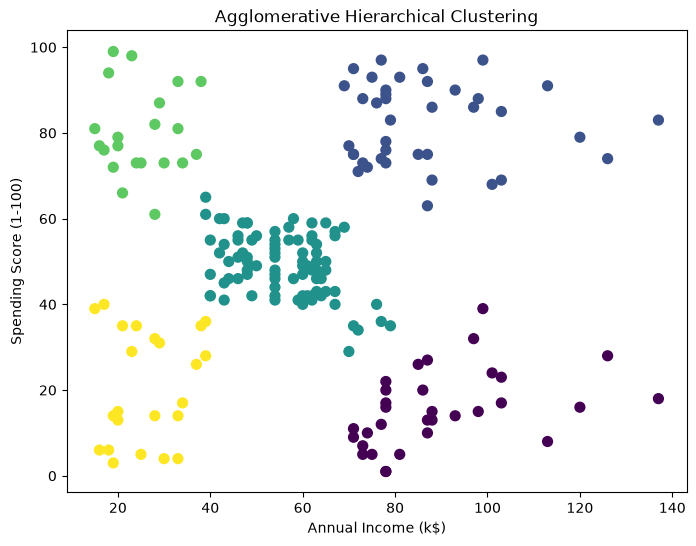

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
data = pd.read_csv("Mall_Customers.csv")

print("Dataset Shape:", data.shape)

print("\nFirst 5 rows:")
print(data.head())
X = data[
    [
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]
]

print("Selected Features:")
print(X.head())
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized data:")
print(X_scaled[:5])
linked = linkage(X_scaled, method='ward')

print("Linkage matrix created successfully.")
plt.figure(figsize=(10, 6))

dendrogram(linked)

plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")

plt.show()
model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)

data['Cluster'] = clusters
print("Cluster Assignments:")

print(data[
        ['CustomerID', 'Annual Income (k$)',
         'Spending Score (1-100)', 'Cluster']].head(10)
)
plt.figure(figsize=(8, 6))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=data['Cluster'],
    s=50
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Agglomerative Hierarchical Clustering")

plt.show()
